# 03 · What can pretraining add? Pretrained word vectors, and an honest note on a pretrained translator

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/Translation-spanish-english/blob/master/notebooks/03_pretrained_word_vectors_and_the_pretrained_model_question.ipynb)

**What this notebook does.** Notebooks 01 and 02 trained everything from zero on 30,000 sentence pairs. Here we ask what *pretraining* can add. The plan was a comparison with a **pretrained translation model**; I could not run one in my environment (section 2 says exactly what was blocked).
What I could do honestly is a smaller, clearly labelled experiment: start the English side of the attention model from **pretrained word vectors (GloVe)** and compare it with notebook 02's model on the same 2,000 test sentences. Then we put all results in one picture ("then vs now").

*Time: about 45 minutes (two training cells of about 13 minutes each on a laptop CPU, plus a 69 MB download). Prerequisite: notebook 02.*

## 1 · The big question

A model trained on 30,000 pairs knows English only from those 30,000 sentences. A person starting to learn Spanish already knows what English words *mean*.
**If we give the model the meaning of English words in advance, does it translate better, with exactly the same data and settings?**

> **Predict:** will pretrained vectors help more in the first epochs or at the end? Will the final BLEU rise by about 1, 3 or 10 points?

## 2 · What I wanted to do, and what was blocked

The goal of part 3 was to compare with a real **pretrained translation model** on the same test sentences. I tried, in this order, and report exactly what happened (the environment I use reaches the internet only through a proxy with an allow-list):

| What I tried | Result |
|---|---|
| A translation model from the Hugging Face hub (`huggingface.co`) | host refused by the proxy |
| Argos Translate models (`argos-net.com`) and the Helsinki-NLP files on `object.pouta.csc.fi`, `zenodo.org` | hosts refused by the proxy |
| The `translatelocally.com` model registry | host refused by the proxy |
| The Mozilla Firefox Translations English→Spanish model on `storage.googleapis.com` | **downloaded** (31.6 MB, checksum verified), but its runtime package (`bergamot`) cannot even be imported offline (its import fetches a file from `translatelocally.com`), and the workaround of loading its compiled extension directly was not permitted in my environment, so I did not use it |

So **there is no pretrained-translation-model number in this repository**, and none is implied. You can run that comparison yourself where the hub is reachable (for example on Google Colab): translate the 2,000 test sentences with a pretrained model and score them with `tr.corpus_bleu(hypotheses, references)` as below. Remember that such a model was trained on millions of pairs, probably including Tatoeba sentences, so a comparison on this test set would not be a clean test of generalisation.

What I *could* do: GloVe word vectors are downloadable from a GitHub release. They are **pretrained embeddings** (a different, much smaller thing than a pretrained translator), and they let us study the effect of pretraining under controlled conditions.

## 3 · Intuition: arriving with a dictionary of meanings

**GloVe** (Pennington, Socher and Manning, 2014) gives each English word a list of numbers (here 50) learned from about 6 billion words of Wikipedia and news text, so that words used in similar contexts get similar numbers: *cat* is near *dog*, far from *train*.
In notebooks 01 and 02 the English embedding table started as random numbers and was learned from our 30,000 sentences. Now its first 50 coordinates (of 128) start from GloVe; the other 78 coordinates and the words GloVe does not know start as small random numbers, and **everything is still trained**, so the model may adjust them.
Only the *starting point* of one table changes: the data, split, vocabularies, sizes, seed, optimiser and number of epochs are the same as in notebook 02.

*Licence:* the vectors come from the `gensim-data` project's release `glove-wiki-gigaword-50`, which lists the licence as the Open Data Commons PDDL (public domain dedication); I could not open the Stanford page to confirm it. Nothing from the download is stored in this repository.

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once (and install sacrebleu).
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/Translation-spanish-english.git"], check=True)
    os.chdir("Translation-spanish-english/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import translation as tr            # import before TensorFlow: it sets two environment variables
from src.translation import save_figure

tr.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

## 4 · Same data, same split, same settings

In [2]:
import keras

pairs = tr.load_pairs()
train, validation, test = tr.make_split(pairs)
train_pairs, validation_pairs, test_pairs = tr.flatten(train), tr.flatten(validation), tr.flatten(test)
source_vocab = tr.Vocabulary([tr.tokenize(e) for e, _ in train_pairs], 6000)
target_vocab = tr.Vocabulary([tr.tokenize(s) for _, s in train_pairs], 8000)

source, decoder_in, decoder_out = tr.encode_pairs(train_pairs, source_vocab, target_vocab)
val_source, val_decoder_in, val_decoder_out = tr.encode_pairs(validation_pairs, source_vocab, target_vocab)
test_english = list(test)
test_source, _, _ = tr.encode_pairs([(e, "") for e in test_english], source_vocab, target_vocab)
references = [test[e] for e in test_english]
print(f"train {len(train_pairs):,} pairs, validation {len(validation_pairs):,} pairs, test {len(test_english):,} English sentences")

train 30,001 pairs, validation 2,424 pairs, test 2,000 English sentences


## 5 · Download the vectors and see how many of our words they cover

`keras.utils.get_file` downloads once (to `~/.keras/datasets`) and **checks the SHA-256 checksum** written in `src/translation.py`; a different file would raise an error.

In [3]:
glove_path = tr.download_glove()
glove_matrix, found, missing = tr.glove_source_matrix(glove_path, source_vocab, embedding=128, return_missing=True)

n_tokens = sum(len(tr.tokenize(e)) for e, _ in train_pairs)
missing_set = set(missing)
n_missing = sum(token in missing_set for e, _ in train_pairs for token in tr.tokenize(e))
print(f"words of our English vocabulary (without the 4 special tokens): {len(source_vocab) - 4:,}")
print(f"found in GloVe: {found:,}; not found: {len(missing)} -> {missing}")
print(f"share of the English words in the training sentences that GloVe covers: {1 - n_missing / n_tokens:.2%}")

words of our English vocabulary (without the 4 special tokens): 5,996
found in GloVe: 5,991; not found: 5 -> ['hadn', 'mustn', 'housesitting', 'impoliteness', 'gossipers']
share of the English words in the training sentences that GloVe covers: 99.99%


**What to notice.** **5,991 of our 5,996 English words are in GloVe** (the five missing ones are *hadn*, *mustn* (pieces of contractions split by our tokeniser), *housesitting*, *impoliteness* and *gossipers*), and the words GloVe covers make up 99.99% of the English words in the training sentences. So almost every English word starts with a meaningful vector; the missing ones keep a small random start.

## 6 · Train both models

Same function as in notebook 02. First the attention model from random embeddings (it should reproduce notebook 02: same seed, same settings), then the one that starts from GloVe.

In [4]:
def train_model(label, source_embeddings=None):
    tr.set_seed()
    model, encoder, decoder = tr.build_attention_seq2seq(len(source_vocab), len(target_vocab), embedding=128, units=256,
                                                         source_embeddings=source_embeddings)
    model.compile(optimizer=keras.optimizers.Adam(2e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    start = time.time()
    history = model.fit([source, decoder_in], decoder_out, batch_size=128, epochs=12,
                        validation_data=([val_source, val_decoder_in], val_decoder_out), callbacks=[stop], verbose=0).history
    print(f"{label}: {model.count_params():,} parameters, trained for {len(history['loss'])} epochs in {time.time() - start:.0f} s")
    print("   validation loss per epoch:", [round(v, 2) for v in history["val_loss"]])
    return encoder, decoder, history

rand_encoder, rand_decoder, rand_history = train_model("attention, random start (notebook 02)")

attention, random start (notebook 02): 4,767,808 parameters, trained for 12 epochs in 804 s
   validation loss per epoch: [2.9, 2.55, 2.26, 2.05, 1.81, 1.6, 1.46, 1.36, 1.32, 1.28, 1.27, 1.28]


In [5]:
glove_encoder, glove_decoder, glove_history = train_model("attention, English embeddings start from GloVe", glove_matrix)

attention, English embeddings start from GloVe: 4,767,808 parameters, trained for 12 epochs in 769 s
   validation loss per epoch: [3.21, 3.07, 2.89, 2.33, 1.89, 1.56, 1.39, 1.28, 1.22, 1.19, 1.19, 1.18]


**What to notice.** - Both models have the same 4,767,808 parameters and ran all 12 epochs (about 800 s and 770 s on this machine). The random-start model reproduces notebook 02 exactly (the same twelve validation losses, best 1.27 at epoch 11).
- **The GloVe model is worse at first** (validation loss 3.21 after epoch 1 against 2.90, and still behind at epochs 2 to 5) because the pretrained numbers are on a different scale from what the rest of the network expects and must be adapted to. **From epoch 6 it is ahead** (1.56 against 1.60) and ends at 1.18 (epoch 12, still falling slowly) against 1.27 at its best. So the answer to the prediction is: the help comes at the end, not at the start.

## 7 · The test: the same 2,000 unseen sentences

In [6]:
rand_hyp, _ = tr.translate_with_attention(rand_encoder, rand_decoder, test_source, target_vocab)
glove_hyp, _ = tr.translate_with_attention(glove_encoder, glove_decoder, test_source, target_vocab)

def exact(hyps):
    return np.mean([" ".join(h) in [" ".join(tr.tokenize(r)) for r in refs] for h, refs in zip(hyps, references)])

BASELINE_BLEU = 11.2          # notebook 01 (re-trained and reproduced in notebook 02); not re-trained here
rows = {"attention, random start": rand_hyp, "attention, GloVe start": glove_hyp}
print(f"{'':26s} {'BLEU':>6s} {'exact match':>12s}")
print(f"{'no attention (nb 01/02)':26s} {BASELINE_BLEU:6.1f} {'1.8%':>12s}   (taken from notebook 02)")
for name, hyps in rows.items():
    print(f"{name:26s} {tr.corpus_bleu(hyps, references):6.1f} {exact(hyps):12.1%}")

lengths = np.array([len(tr.tokenize(e)) for e in test_english])
groups = {"1-4": (1, 4), "5-7": (5, 7), "8-10": (8, 10)}
print("\nBLEU by English length (words and punctuation marks):")
for g, (lo, hi) in groups.items():
    idx = np.where((lengths >= lo) & (lengths <= hi))[0]
    scores = [tr.corpus_bleu([h[i] for i in idx], [references[i] for i in idx]) for h in (rand_hyp, glove_hyp)]
    print(f"  {g:5s} ({len(idx):4d} sentences): random {scores[0]:5.1f}   GloVe {scores[1]:5.1f}")

diff = tr.bootstrap_bleu_difference(glove_hyp, rand_hyp, references)
print(f"\nGloVe minus random start: {tr.corpus_bleu(glove_hyp, references) - tr.corpus_bleu(rand_hyp, references):+.1f} BLEU; "
      f"95% interval over test sentences {np.percentile(diff, 2.5):+.1f} to {np.percentile(diff, 97.5):+.1f}; "
      f"GloVe ahead in {np.mean(diff > 0):.0%} of {len(diff)} resamples")

                             BLEU  exact match
no attention (nb 01/02)      11.2         1.8%   (taken from notebook 02)


attention, random start      25.8         8.8%
attention, GloVe start       28.9         9.8%

BLEU by English length (words and punctuation marks):
  1-4   ( 159 sentences): random  25.5   GloVe  36.7


  5-7   (1092 sentences): random  27.6   GloVe  30.4
  8-10  ( 749 sentences): random  24.1   GloVe  26.9



GloVe minus random start: +3.1 BLEU; 95% interval over test sentences +2.0 to +4.3; GloVe ahead in 100% of 200 resamples


**What to notice.** - **BLEU 25.8 → 28.9 (+3.1)** and exact match 8.8% → 9.8%. The paired bootstrap over the test sentences gives +2.0 to +4.3 (95%), and GloVe is ahead in all 200 resamples. (The no-attention model of notebook 01 scores 11.2 and is quoted from notebook 02, not re-trained.)
- It helps at every length: +11.2 for the shortest sentences (1-4 words; only 159 sentences, so this number is noisy), +2.8 for 5-7 and +2.8 for 8-10 words.
- Caveats: one training run per model, so the difference between two seeds is unmeasured; and the interval covers only the choice of test sentences.

## 8 · A look at the translations

The first sentences of the test list (not chosen by quality), with one reference each:

In [7]:
for i in range(8):
    print(f"English : {test_english[i]}")
    print(f"random  : {' '.join(rand_hyp[i])}")
    print(f"GloVe   : {' '.join(glove_hyp[i])}")
    print(f"correct : {references[i][0]}\n")

English : I bought two pairs of trousers.
random  : compré dos de detectives .
GloVe   : compré dos de gafas .
correct : Compré dos pares de pantalones.

English : Tom died from tuberculosis.
random  : tom murió de la mano .
GloVe   : tom murió de sus .
correct : Tom murió de tuberculosis.

English : Will it be hot again tomorrow?
random  : ¿ usted calor mañana ?
GloVe   : ¿ por favor mañana mañana , ¿ día ?
correct : ¿Mañana volverá a hacer calor?

English : I don't know how to swim.
random  : no sé cómo nadar .
GloVe   : no sé cómo nadar .
correct : No sé nadar.

English : Tom stabbed Mary repeatedly with his knife.
random  : tom le mostró a mary con sus cuchillo .
GloVe   : tom le disparó a mary con su cuchillo .
correct : Tom apuñaló a Mary repetidamente con su cuchillo.

English : I don't remember inviting you.
random  : no me acuerdo de .
GloVe   : no me acuerdo de invitarme .
correct : No recuerdo haberte invitado.

English : Where did you buy this motorcycle?
random  : ¿ dónde 

**What to notice.** The better BLEU does not mean every sentence improves. In these eight, both models make most of the same mistakes (*detectives* or *gafas* instead of *pantalones*; neither knows *tuberculosis* or *apuñaló*); GloVe fixes none of them clearly, gets *invitarme* ("invite me") where the correct meaning is "invited you", writes the wrong gender in *este moto* (random start has the right *esta moto*) and repeats a word in *hacer hacer* and *mañana mañana*. The gain is an average over 2,000 sentences, not a visible improvement on every example.

## 9 · Then vs now: one conclusion plot

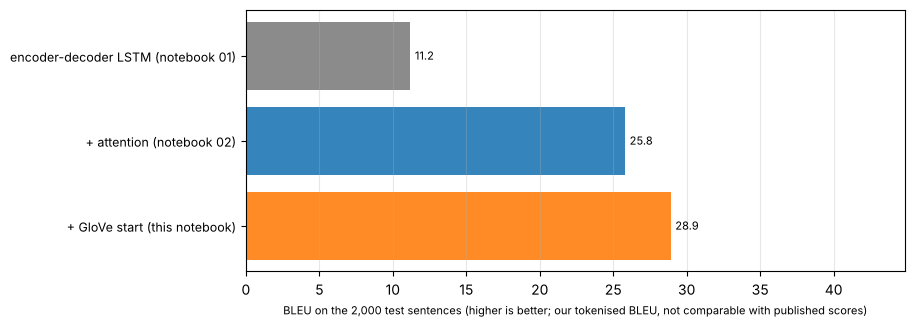

In [8]:
names = ["encoder-decoder LSTM (notebook 01)", "+ attention (notebook 02)", "+ GloVe start (this notebook)"]
scores = [BASELINE_BLEU, tr.corpus_bleu(rand_hyp, references), tr.corpus_bleu(glove_hyp, references)]
fig = tr.plot_conclusion(names, scores, ["", "", ""])
save_figure(fig, "03_conclusion.png")
plt.show()

**What to notice.** The step from the baseline to attention (+14.6 BLEU) is much larger than the step from random to pretrained English vectors (+3.1). Attention changed the structure of the model; GloVe only changed one starting table. Both are real, measured differences on the same test sentences, but the plot does *not* tell how far we are from a real pretrained translator, because that bar is missing.

*Figure: BLEU of the three models on the same 2,000 test sentences. There is no bar for a pretrained translation model because I could not run one (section 2).*

## 10 · Common mistakes

- **Calling this "a pretrained translation model".** GloVe gives *word meanings* for the English side only; the translator itself (encoder, decoder, attention, the whole Spanish side) is still trained from zero on 30,000 pairs.
- **Trusting one training run.** The bootstrap resamples the *test sentences*; it does not measure the variation between training runs with different seeds, which I did not run (each training costs about 13 minutes).
- **Comparing BLEU with published scores.** Ours uses lower-cased words and punctuation marks as tokens and several references; it is only comparable inside this repository.
- **Comparing with a model that has seen the test sentences.** Large pretrained translators were trained on web-scale data that probably contains Tatoeba sentences.

## 11 · Recap

- Starting the English embeddings from GloVe changes only the starting point of one table, yet it changes the training curve and the final score (numbers in section 7).
- All three models of this repository sit in one picture: baseline, attention, attention with pretrained vectors.
- The comparison with a real pretrained translator is **not done**: the hosts that serve such models are blocked in my environment.

**Where to go next:** train with several seeds; also initialise the Spanish side (with Spanish vectors); try a Transformer; run a pretrained translator where the hub is reachable.